
# Graph Neural Networks from Scratch — Tutorial 3: Training a GCN with PyTorch

### From a graph convolution forward pass to learning through backpropagation

*📺 Video on YouTube | 🐍 Python · NumPy · PyTorch | Beginner–Intermediate*

*Notebook repository: [github.com/rraj-io/GNN-Tutorials](https://github.com/rraj-io/GNN-Tutorials)*

---

## Series Roadmap

In Tutorial 1, we learned how graphs represent connected data through nodes, edges, adjacency matrices, and node features.

In Tutorial 2, we took the next step by implementing a **Graph Convolutional Network (GCN) forward pass from scratch using NumPy**. We explored self-loops, degree matrices, graph normalization, and neighbourhood aggregation to understand how information flows through a graph.

But so far, our GCN could only perform a forward pass. It could transform node features, but it could not learn from data.

In this tutorial, we will change that.

We will introduce **PyTorch** and turn our GCN into a trainable neural network. We will explore how learnable parameters are updated through gradients and backpropagation, and how a GCN can learn to classify nodes based on their features and graph structure.

The focus is not just on writing a training loop. We want to understand what happens at every stage of the learning process, from the forward pass to the weight updates.

| # | Tutorial | Focus | Status |
|---|---|---|---|
| 1 | Graph Fundamentals and Representations | nodes, edges, adjacency matrices, graph features | ✅ |
| 2 | Graph Convolutional Networks from Scratch | propagation, normalization, NumPy implementation | ✅ |
| **3** | **Training a GCN with PyTorch** | **learnable parameters, backpropagation, node classification** | **📍 You are here** |
| 4 | PyTorch Geometric and the Cora Dataset | practical GNN implementation, real graph dataset | Planned |
| 5 | Message Passing Neural Networks | message, aggregate, update, custom GNN layers | Planned |
| 6 | Graph Attention Networks (GAT) | attention-based neighbourhood aggregation | Planned |
| 7 | GraphSAGE and Advanced Aggregation | scalable neighbourhood learning | Planned |
| 8 | Graph-Level Learning | graph classification and regression | Planned |
| 9 | GNNs for Mesh-Based Systems | mesh connectivity, geometric features, scientific data | Planned |
| 10 | GNNs for Scientific Machine Learning | surrogate modelling and engineering applications | Planned |

The goal is to progress from understanding graph representations to building trainable models that can learn from complex connected systems, including computational meshes and physical systems.
<!--
## What will we learn?

In this tutorial, we will introduce the essential components of neural network training:

- PyTorch tensors and automatic differentiation.
- Learnable parameters and `nn.Module`.
- Forward propagation and model predictions.
- Logits and cross-entropy loss.
- Gradients and backpropagation.
- Gradient-based optimization using an optimizer.
- Training loops and model evaluation.
- Node classification using a GCN.

We will begin with a simple learning example to understand how PyTorch updates a parameter. Then, we will apply the same principles to our GCN.
-->

## The learning process

A trainable GCN follows an iterative learning process:

```text
          Graph + Node Features
                    |
                    v
                  GCN
                    |
                    v
                  Logits
                    |
                    v
              Calculate Loss
                    |
                    v
             Backpropagation
                    |
                    v
                Gradients
                    |
                    v
              Update Weights
                    |
                    v
              Repeat Training
```

Unlike the NumPy implementation in Tutorial 2, the weights in this model are now trainable. The network learns by comparing its predictions with the target labels and adjusting its parameters to reduce the prediction error.

> **New to PyTorch?** Don't worry if you haven't trained a neural network before. We will first introduce tensors, automatic differentiation, and a simple optimization example before building the complete GCN training pipeline. A basic understanding of Python, NumPy, and the GCN equation from Tutorial 2 will be helpful.
>
> If you're interested in scientific machine learning, CFD, or computational mechanics, pay attention to how the GCN learns from graph connectivity. The same learning principles can later be applied to unstructured computational meshes, where nodes or cells exchange information to predict physical quantities.

**Let's now move from a GCN that can perform graph convolution to one that can actually learn.**


# 1 — What changed from Tutorial 2?

In Tutorial 2 we used

$$
H^{(1)}=\mathrm{ReLU}(SXW)
$$

where $W$ was chosen manually.

A real neural network must **learn $W$ from data**.

The learning process is:

$$
\boxed{
\text{prediction}
\rightarrow
\text{loss}
\rightarrow
\text{gradient}
\rightarrow
\text{weight update}
}
$$

The GCN differs from an ordinary neural network because the graph propagation matrix $S$ uses the graph structure.



# 2 — Setting up PyTorch

PyTorch gives us:

1. **Tensors** — arrays that can participate in automatic differentiation.
2. **Parameters** — values that can be learned.
3. **Autograd** — automatic calculation of derivatives.

Let's check the environment.


In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch version:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")


PyTorch version: 2.11.0+cu130
Device: cpu


# 3 — NumPy arrays vs PyTorch tensors

In Tutorial 2 we used NumPy arrays. Now we use PyTorch tensors.

A tensor looks familiar.

$$
X =
\begin{bmatrix}
1 & 0\\
0 & 1
\end{bmatrix}
$$

but PyTorch can also track operations needed for gradients.


In [2]:

X_demo = torch.tensor([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0]
])

print(X_demo)
print("Shape:", X_demo.shape)
print("Data type:", X_demo.dtype)


tensor([[1., 0.],
        [0., 1.],
        [1., 1.]])
Shape: torch.Size([3, 2])
Data type: torch.float32



### 🧪 Hands-on Exercise 1

Create a PyTorch tensor containing:

```text
[1, 2, 3]
[4, 5, 6]
```

Then print its tensor, shape, mean, and maximum value.


In [ ]:

# YOUR CODE HERE

# tensor = ...
# print(...)


In [3]:

# Solution

tensor = torch.tensor([
    [1.0, 2.0, 3.0],
    [4.0, 5.0, 6.0]
])

print(tensor)
print("Shape:", tensor.shape)
print("Mean:", tensor.mean())
print("Maximum:", tensor.max())


tensor([[1., 2., 3.],
        [4., 5., 6.]])
Shape: torch.Size([2, 3])
Mean: tensor(3.5000)
Maximum: tensor(6.)



# 4 — What does "learning" actually mean?

Forget GNNs for a moment.

Consider:

$$
y=wx
$$

Suppose $x=2$, the desired output is $10$, and the current weight is $w=2$.

Then:

$$
y=4
$$

A simple loss is:

$$
L=(y_{\text{pred}}-y_{\text{true}})^2
$$

We want to know how changing $w$ changes $L$:

$$
\frac{\partial L}{\partial w}
$$

That derivative is the **gradient**.


In [4]:

w = torch.tensor(2.0, requires_grad=True)

x = torch.tensor(2.0)
y_true = torch.tensor(10.0)

y_pred = w * x
loss = (y_pred - y_true) ** 2

loss.backward()

print("Prediction:", y_pred.item())
print("Loss:", loss.item())
print("Gradient dw:", w.grad.item())


Prediction: 4.0
Loss: 36.0
Gradient dw: -24.0


The important line is:

```python
loss.backward()
```

PyTorch calculates the derivative automatically.

Gradient descent then updates the parameter:

$$
w_{\text{new}}
=
w_{\text{old}}
-
\eta
\frac{\partial L}{\partial w}
$$

where $\eta$ is the learning rate.



# 5 — A tiny training loop

Before introducing a GCN, let's make the training process explicit:

```text
initialize weight
       ↓
forward pass
       ↓
calculate loss
       ↓
calculate gradient
       ↓
update weight
       ↓
repeat
```


In [5]:

w = torch.tensor(0.0, requires_grad=True)

x = torch.tensor(2.0)
y_true = torch.tensor(10.0)
learning_rate = 0.1

for epoch in range(20):

    y_pred = w * x
    loss = (y_pred - y_true) ** 2

    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad

    w.grad.zero_()

    if epoch % 2 == 0:
        print(
            f"Epoch {epoch:2d} | "
            f"w = {w.item():.4f} | "
            f"loss = {loss.item():.4f}"
        )


Epoch  0 | w = 4.0000 | loss = 100.0000
Epoch  2 | w = 4.9600 | loss = 0.1600
Epoch  4 | w = 4.9984 | loss = 0.0003
Epoch  6 | w = 4.9999 | loss = 0.0000
Epoch  8 | w = 5.0000 | loss = 0.0000
Epoch 10 | w = 5.0000 | loss = 0.0000
Epoch 12 | w = 5.0000 | loss = 0.0000
Epoch 14 | w = 5.0000 | loss = 0.0000
Epoch 16 | w = 5.0000 | loss = 0.0000
Epoch 18 | w = 5.0000 | loss = 0.0000



Notice the five steps:

```python
y_pred = ...             # forward
loss = ...               # loss
loss.backward()          # gradients
w -= ...                 # update
w.grad.zero_()           # reset
```

Later, a PyTorch optimizer will automate the parameter update.



# 6 — Return to the GCN

Our GCN equation is:

$$
H^{(l+1)}
=
\sigma(SH^{(l)}W^{(l)})
$$

At the first layer:

$$
H^{(0)}=X
$$

so:

$$
H^{(1)}=\sigma(SXW)
$$

The crucial change is that $W$ is now a **learnable PyTorch parameter**.



# 7 — Build a small graph dataset

We will use a small synthetic graph and perform **node classification**.

The goal is:

$$
(A,X)
\rightarrow
\text{GCN}
\rightarrow
\hat y
$$

where $y$ contains the target class for every node.


In [6]:

nodes = ["Alice", "Bob", "Charlie", "David", "Eve"]

edges = [
    ("Alice", "Bob"),
    ("Alice", "Charlie"),
    ("Bob", "David"),
    ("Charlie", "Eve"),
    ("David", "Eve"),
]

node_to_id = {node: i for i, node in enumerate(nodes)}

A = torch.zeros((len(nodes), len(nodes)))

for a, b in edges:
    i = node_to_id[a]
    j = node_to_id[b]
    A[i, j] = 1.0
    A[j, i] = 1.0

X = torch.tensor([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0],
    [0.0, 0.0],
    [1.0, 0.0]
])

# Two classes: 0 and 1
y = torch.tensor([0, 1, 0, 1, 0])

print("A:")
print(A)

print("\nX:")
print(X)

print("\ny:")
print(y)


A:
tensor([[0., 1., 1., 0., 0.],
        [1., 0., 0., 1., 0.],
        [1., 0., 0., 0., 1.],
        [0., 1., 0., 0., 1.],
        [0., 0., 1., 1., 0.]])

X:
tensor([[1., 0.],
        [0., 1.],
        [1., 1.],
        [0., 0.],
        [1., 0.]])

y:
tensor([0, 1, 0, 1, 0])


We now have:

- $A$ — graph structure
- $X$ — node features
- $y$ — target labels

The learning problem is:

$$
(A,X)\rightarrow \text{GCN} \rightarrow \hat y
$$


# 8 — Normalize the adjacency matrix with PyTorch

From Tutorial 2:

$$
S=
\hat D^{-1/2}
\hat A
\hat D^{-1/2}
$$

Let's make this reusable.


In [7]:

def normalized_adjacency(A):
    A_hat = A + torch.eye(A.shape[0], dtype=A.dtype)

    degrees = A_hat.sum(dim=1)

    D_inv_sqrt = torch.diag(
        1.0 / torch.sqrt(degrees)
    )

    S = D_inv_sqrt @ A_hat @ D_inv_sqrt

    return S


S = normalized_adjacency(A)

print("Normalized adjacency:")
print(S)


Normalized adjacency:
tensor([[0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.0000, 0.3333, 0.0000],
        [0.3333, 0.0000, 0.3333, 0.0000, 0.3333],
        [0.0000, 0.3333, 0.0000, 0.3333, 0.3333],
        [0.0000, 0.0000, 0.3333, 0.3333, 0.3333]])



### 🧪 Hands-on Exercise 2

Modify `normalized_adjacency()` so it prints:

- the degree of every node
- the shape of `A_hat`
- the shape of `S`

Then verify:

```python
S.shape == A.shape
```

Checking tensor shapes is one of the most useful neural-network debugging habits.


# 9 — Build the GCN as a PyTorch module

Our mathematical layer is:

$$
H=\mathrm{ReLU}(SXW)
$$

In PyTorch, we make $W$ trainable with:

```python
nn.Parameter(...)
```


In [8]:

class SimpleGCN(nn.Module):

    def __init__(self, in_features, out_features):
        super().__init__()

        self.W = nn.Parameter(
            torch.randn(in_features, out_features) * 0.1
        )

    def forward(self, X, S):
        H = S @ X
        H = H @ self.W
        H = F.relu(H)
        return H


model = SimpleGCN(
    in_features=2,
    out_features=2
)

print(model)
print("\nLearnable parameter:")
print(model.W)


SimpleGCN()

Learnable parameter:
Parameter containing:
tensor([[-0.1933, -0.1066],
        [ 0.1528, -0.1360]], requires_grad=True)


The code follows the equation directly:

$$
H=\mathrm{ReLU}(SXW)
$$

becomes:

```python
H = S @ X
H = H @ self.W
H = F.relu(H)
```

This is why the from-scratch work in Tutorials 1 and 2 is useful: `SimpleGCN` is no longer a black box.


# 10 — Forward pass

In [9]:

logits = model(X, S)

print("Logits:")
print(logits)

print("\nShape:", logits.shape)


Logits:
tensor([[0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.]], grad_fn=<ReluBackward0>)

Shape: torch.Size([5, 2])



We have two output values per node:

```text
             Class 0     Class 1
Alice          ...         ...
Bob            ...         ...
Charlie        ...         ...
David          ...         ...
Eve            ...         ...
```

These are **logits**.

For node $i$:

$$
z_i=[z_{i,0},z_{i,1}]
$$

The larger value is the model's current preference for that class.



# 11 — Cross-entropy loss

We need a number describing how wrong the predictions are.

For classification, we use cross-entropy:

```python
loss_fn = nn.CrossEntropyLoss()
loss = loss_fn(logits, y)
```

Conceptually:

$$
\boxed{\text{logits}\rightarrow\text{loss}}
$$


In [10]:

loss_fn = nn.CrossEntropyLoss()

loss = loss_fn(logits, y)

print("Loss:", loss.item())


Loss: 0.6931471824645996



### Important beginner note

For `CrossEntropyLoss`, do **not** apply softmax first.

Use:

```python
loss = loss_fn(logits, y)
```

PyTorch handles the required log-softmax operation internally in a numerically stable way.



# 12 — Backpropagation

Now we have a loss.

PyTorch calculates the gradient of the loss with respect to every learnable parameter:

```python
loss.backward()
```


In [11]:

loss.backward()

print("Gradient of W:")
print(model.W.grad)


Gradient of W:
tensor([[0., 0.],
        [0., 0.]])


The gradient contains:

$$
\frac{\partial L}{\partial W}
$$

It tells us how the loss changes when the GCN weights change.



# 13 — The optimizer

Manual gradient descent is:

$$
W\leftarrow W-\eta\nabla_W L
$$

PyTorch provides optimizers such as Adam:

```python
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)
```

The standard training step becomes:

```python
optimizer.zero_grad()
loss.backward()
optimizer.step()
```

Think of these as:

```text
clear old gradients
        ↓
calculate new gradients
        ↓
update parameters
```


# 14 — Our first complete GCN training loop

In [12]:

model = SimpleGCN(
    in_features=2,
    out_features=2
)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.05
)

num_epochs = 300

for epoch in range(num_epochs):

    # Forward pass
    logits = model(X, S)

    # Loss
    loss = loss_fn(logits, y)

    # Clear old gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update weights
    optimizer.step()

    if epoch % 25 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Loss: {loss.item():.4f}"
        )


Epoch   0 | Loss: 0.6786
Epoch  25 | Loss: 0.5785
Epoch  50 | Loss: 0.5496
Epoch  75 | Loss: 0.5251
Epoch 100 | Loss: 0.5054
Epoch 125 | Loss: 0.4901
Epoch 150 | Loss: 0.4784
Epoch 175 | Loss: 0.4692
Epoch 200 | Loss: 0.4619
Epoch 225 | Loss: 0.4561
Epoch 250 | Loss: 0.4514
Epoch 275 | Loss: 0.4475



If the model is learning, the loss should generally decrease.

We have now gone from:

```text
Graph
+
Node features
+
Random weights
```

to:

```text
Graph
+
Node features
+
Learned weights
→
Predictions
```


# 15 — Inspect the predictions

In [13]:
with torch.no_grad():
    logits = model(X, S)
    predictions = logits.argmax(dim=1)

print("Logits:")
print(logits)

print("\nPredicted classes:")
print(predictions)

print("\nTrue classes:")
print(y)


Logits:
tensor([[0.2303, 0.0000],
        [0.1152, 0.0000],
        [4.0912, 0.0000],
        [0.1152, 0.0000],
        [2.1032, 0.0000]])

Predicted classes:
tensor([0, 0, 0, 0, 0])

True classes:
tensor([0, 1, 0, 1, 0])


In [14]:

accuracy = (predictions == y).float().mean()

print(f"Accuracy: {accuracy.item() * 100:.1f}%")


Accuracy: 60.0%



`argmax(dim=1)` selects the class with the largest logit.

For example:

```text
logits = [1.2, 3.7]
```

means the predicted class is `1`.

The model has now learned a mapping from graph structure + node features to node labels.



### 🧪 Hands-on Exercise 3 — Change the labels

Change `y` to a different classification problem, for example:

```python
y = torch.tensor([1, 0, 1, 0, 1])
```

Retrain the model.

Ask:

1. Does the loss decrease?
2. Does the model reach 100% training accuracy?
3. Do the learned weights change?
4. Are some label assignments harder to learn?



# 16 — Plot the training curve

A final loss value is useful, but the training history tells us more.

Let's record:

$$
L(t)
$$

over the epochs.


In [15]:

model = SimpleGCN(2, 2)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.05
)

loss_fn = nn.CrossEntropyLoss()

loss_history = []

for epoch in range(300):

    logits = model(X, S)
    loss = loss_fn(logits, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())


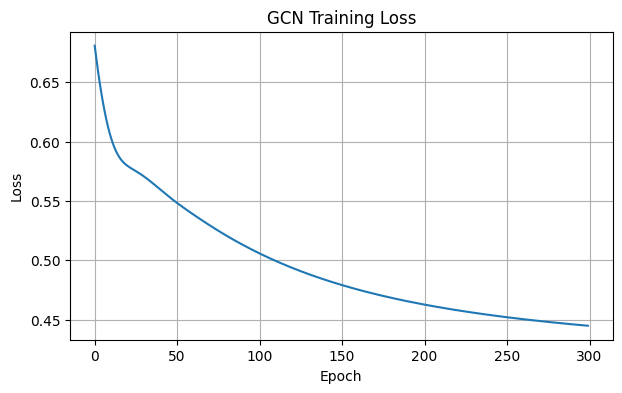

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GCN Training Loss")
plt.grid(True)
plt.show()



### 🧪 Hands-on Exercise 4 — Experiment with learning rate

Train the same GCN using:

```text
0.001
0.01
0.05
0.5
```

Plot the loss curves.

Think about:

- Which rate learns slowly?
- Which changes rapidly?
- Can the learning rate be too large?
- Why can a large learning rate make training unstable?



# 17 — Training on only some nodes

A major idea in graph learning is that we do not necessarily need labels for every node.

For example:

```text
Alice    → labelled
Bob      → labelled
Charlie  → labelled
David    → unknown
Eve      → unknown
```

We can still calculate representations for **all** nodes, but calculate the loss only on labelled nodes.

This is the basic idea behind **semi-supervised node classification**.

A mask can identify training nodes:

```python
train_mask = torch.tensor([
    True,
    True,
    True,
    False,
    False
])
```

Then:

```python
loss = loss_fn(
    logits[train_mask],
    y[train_mask]
)
```



### 🧪 Hands-on Exercise 5 — Train with a mask

Create the mask above and modify the training loop so that only Alice, Bob, and Charlie contribute to the loss.

After training, predict all five nodes.

**Question:** Why can the model produce predictions for David and Eve even though they were not directly included in the loss?



# 18 — Two-layer GCN

A two-layer GCN is:

$$
H^{(1)}
=
\mathrm{ReLU}(SXW^{(0)})
$$

followed by:

$$
Z=SH^{(1)}W^{(1)}
$$

where $Z$ contains the final class logits.


In [17]:

class TwoLayerGCN(nn.Module):

    def __init__(self, in_features, hidden_features, num_classes):
        super().__init__()

        self.W1 = nn.Parameter(
            torch.randn(in_features, hidden_features) * 0.1
        )

        self.W2 = nn.Parameter(
            torch.randn(hidden_features, num_classes) * 0.1
        )

    def forward(self, X, S):

        H = S @ X
        H = H @ self.W1
        H = F.relu(H)

        Z = S @ H
        Z = Z @ self.W2

        return Z


model = TwoLayerGCN(
    in_features=2,
    hidden_features=4,
    num_classes=2
)

print(model)


TwoLayerGCN()



The computation is:

```text
X
│
▼
S @ X
│
▼
W1
│
▼
ReLU
│
▼
S @ H1
│
▼
W2
│
▼
logits
```

or:

$$
\boxed{
Z =
S\\,
\mathrm{ReLU}(SXW^{(0)})
W^{(1)}
}
$$

The second layer performs another graph propagation step, allowing information to travel farther through the graph.


# 19 — Train the two-layer GCN

In [18]:

model = TwoLayerGCN(
    in_features=2,
    hidden_features=4,
    num_classes=2
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.05
)

loss_fn = nn.CrossEntropyLoss()

loss_history = []

for epoch in range(500):

    logits = model(X, S)
    loss = loss_fn(logits, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Loss: {loss.item():.4f}"
        )


Epoch   0 | Loss: 0.6934
Epoch  50 | Loss: 0.5313
Epoch 100 | Loss: 0.4118
Epoch 150 | Loss: 0.3489
Epoch 200 | Loss: 0.2977
Epoch 250 | Loss: 0.2862
Epoch 300 | Loss: 0.2832
Epoch 350 | Loss: 0.2813
Epoch 400 | Loss: 0.2806
Epoch 450 | Loss: 0.2796


In [19]:

with torch.no_grad():
    logits = model(X, S)
    predictions = logits.argmax(dim=1)

accuracy = (predictions == y).float().mean()

print("Predictions:", predictions)
print("Targets:    ", y)
print(f"Accuracy:    {accuracy.item() * 100:.1f}%")


Predictions: tensor([0, 0, 0, 0, 0])
Targets:     tensor([0, 1, 0, 1, 0])
Accuracy:    60.0%



# 20 — 🧪 Final Challenge: Build your own trainable GCN

Now stop copying the previous examples.

Create your own graph with:

- **8 nodes**
- at least **10 edges**
- **3 features per node**
- **3 classes**
- a hidden layer of **5 features**

Build:

$$
X\rightarrow H^{(1)}\rightarrow Z
$$

using:

$$
H^{(1)}=\mathrm{ReLU}(SXW^{(0)})
$$

and:

$$
Z=SH^{(1)}W^{(1)}
$$

Then:

1. Create labels.
2. Train with `CrossEntropyLoss`.
3. Use Adam.
4. Record the loss.
5. Plot the training curve.
6. Calculate final training accuracy.
7. Print predictions.

### Bonus

Use a `train_mask` so only some nodes contribute to the loss.



# 21 — What we learned

We have now gone from a mathematical GCN to an actual trainable neural network.

### Tutorial 1

$$
\text{Graph}
\rightarrow
(A,X)
\rightarrow
\text{message passing}
$$

### Tutorial 2

$$
(A,X)
\rightarrow
S
\rightarrow
SXW
\rightarrow
\text{GCN forward pass}
$$

### Tutorial 3

$$
\text{GCN}
\rightarrow
\text{logits}
\rightarrow
\text{loss}
\rightarrow
\text{gradients}
\rightarrow
\text{weight updates}
$$

The full learning loop is:

```text
Forward pass
     ↓
   Logits
     ↓
    Loss
     ↓
Backpropagation
     ↓
 Gradients
     ↓
Update weights
     ↺
```



# 22 — What comes next?

We now have a working GCN implemented directly in PyTorch.

But we wrote the graph operations ourselves.

The next tutorial introduces:

# Tutorial 4 — PyTorch Geometric

We will learn:

- why PyTorch Geometric exists
- graph data objects
- `edge_index`
- `Data`
- `GCNConv`
- datasets
- train/validation/test masks
- Cora
- node classification
- comparing our implementation with `GCNConv`

The goal is:

> **I know what `GCNConv` is doing because I already built the underlying operation myself.**

---

## 🎯 Series progression

```text
Tutorial 1
Graph
 ↓
A + X
 ↓
Message passing

Tutorial 2
A + I
 ↓
Degree matrix
 ↓
Normalization
 ↓
GCN forward pass

Tutorial 3
GCN
 ↓
Loss
 ↓
Backpropagation
 ↓
Training
 ↓
Learned GNN

Tutorial 4
PyTorch Geometric
 ↓
GCNConv
 ↓
Real dataset
 ↓
Node classification
```
